## 01. Diabetes Complications

In [ ]:
# Useful constants
RANDOM_STATE = 42

## Part 1: Explore the data

### Task 1: Datapreparation

#### Task 1a: Load packages and data

$0^{th}$ **Briefly explain what each package does.**

In [60]:
import math
import sklearn             
import pyarrow              
import numpy as np
import pandas as pd
import xgboost as xgb   
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import sparse
from tableone import TableOne 
from scipy.stats import pearsonr, spearmanr 
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor    
from sklearn.linear_model import LogisticRegression, ElasticNet, Lasso, Ridge

In [ ]:
df = pd.read_parquet("./data_cleaned.parquet")
df = df.sort_values(by = ["pnr", "year_month"]).reset_index(drop = True)

print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")

The dataset has 4982280 rows and 39 columns.


$0^{th}$ **You need to create the year variable by yourself.**

In [4]:
# Adding `year` column to the dataset
years = []
for year_month in df["year_month"]:
    year = int(year_month.split("-")[0])
    years.append(year)

df["year"] = years

In [5]:
display(df.head())

,pnr,debut,dob,P8_male,R5_educ,R25_DADI_9,G4_region_residence_name,R2_single,R3_childrenhome,R4_children18up,...,acsc_t2dm,acsc_epi,acsc_copd,acsc_astma,acsc_heartf,acsc_angina,month_date,month,year_month,year
0,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,0,Syddanmark,0,1,5,...,0,0,0,0,0,0,2014-01-01 02:00:00+02:00,1,2014-01,2014
1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,1,Syddanmark,0,0,11,...,0,0,0,0,0,0,2014-02-01 02:00:00+02:00,2,2014-02,2014
2,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,1,Syddanmark,0,0,3,...,0,0,0,0,0,0,2014-03-01 02:00:00+02:00,3,2014-03,2014
3,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,0,Syddanmark,0,0,2,...,0,0,0,0,0,0,2014-04-01 03:00:00+03:00,4,2014-04,2014
4,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,1,Syddanmark,1,0,1,...,0,0,0,0,0,0,2014-05-01 03:00:00+03:00,5,2014-05,2014


#### Task 1b: How big is the data?

In [6]:
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns")

The dataset has 4982280 rows and 40 columns


$1^{st}$ **How many individuals are there?**

In [7]:
number_people = len(df.groupby("pnr").size())
print(f"The dataset has {number_people} patients")

The dataset has 83038 patients


$2^{nd}$ **How many observations are there per individual?**

In [8]:
sum_observations = df.groupby("pnr").size().sum()
print(f"The dataset has {int(sum_observations / number_people)} observations per person")

The dataset has 60 observations per person


$3^{rd}$ **Which variables does the dataset contain?**

In [9]:
def print_dtype_dict(d: dict):
    _str = "\n"

    for key, value in d.items():
        _str += f"- {key}: {value} \n"

    return _str

In [10]:
dict_dtypes = {}
for column in df.columns:
    feature = df[column]

    if str(feature.dtype) not in dict_dtypes.keys():
        dict_dtypes[str(feature.dtype)] = 1
    else:
        dict_dtypes[str(feature.dtype)] += 1

print(f"The dataset has the following types of features: {print_dtype_dict(dict_dtypes)}")

The dataset has the following types of features: 
- int32: 28 
- datetime64[us, Europe/Athens]: 3 
- str: 2 
- float64: 6 
- int64: 1 



#### Task 1c: What's in the data?

In [ ]:
# Copy of the original dataframe since we are gonna to replace some original values
df_eda = df.copy()

# Replacing `99` missing values with `NaN`
df_eda["smoking"] = df_eda["smoking"].replace(to_replace = 99, value = np.nan)
df_eda["R5_educ"] = df_eda["R5_educ"].replace(to_replace = 99, value = np.nan)

# Converting datetime into numeric
datetimes = ["debut", "dob", "month_date"]
for date_time in datetimes:
    df_eda[date_time] = pd.to_numeric(df_eda[date_time])

In [ ]:
# Displaying dtypes and missing values for each column
dict_missing_values = {}
for column in df_eda.columns[1:]:
    feature = df_eda[column]
    dict_missing_values[feature.name] = [feature.dtypes, feature.isna().sum()]

missing = pd.DataFrame.from_dict(dict_missing_values, orient = "index", columns = ["dtype", "n_missing"])

display(missing)

,dtype,n_missing
debut,int64,0
dob,int64,0
P8_male,int32,0
R5_educ,float64,6227
R25_DADI_9,int32,0
G4_region_residence_name,str,0
R2_single,int32,0
R3_childrenhome,int32,0
R4_children18up,int32,0
R11_disp_income,float64,0


#### Task 1d: Examine the four outcomes

In [ ]:
from tabulate import tabulate

def check_outcomes(outcomes: list, df: pd.DataFrame):
    '''
        Function used to check the selected outcome variable behavior. \n
        **Parameters**:
            **outcome**: outcome variable you want to analyze 
            **df**: dataframe cointaing all the observations
    '''

    table = []
    headers = ["outcome", "share_months", "share_people", "n_patients", "p(outcome|0)", "p(outcome|1)"]
    for outcome in outcomes:
        grouped_by_pnr = df.groupby("pnr")
        n_people = len(grouped_by_pnr)

        # Defining months percetange having the outcome
        share_months = round(df[outcome].mean() * 100, 2)

        # Defining people percentage having the outcome
        people_outcome = round(((grouped_by_pnr[outcome].max()).sum() / n_people) * 100, 2)

        # Counting patients having the specific outcome
        months_per_person = grouped_by_pnr[outcome].sum()
        affected = months_per_person[months_per_person > 0]

        # Computing conditional probabilities
        previous_months = grouped_by_pnr[outcome].shift(1)
        valid = previous_months.notna()

        tb = pd.crosstab(previous_months[valid], df[outcome][valid], normalize = "index") 

        # `p_new_event` get the outcome even though not present the last month
        p_new_event = round((tb[1][0] * 100), 2)

        # `p_event_persist` the outcome continue even though already present the last month
        p_event_persist = round((tb[1][1] * 100), 2)

        table.append([outcome, share_months, people_outcome, len(affected), p_new_event, p_event_persist])
    
    print(tabulate(table, headers = headers))


In [14]:
outcomes = ["tissue_infection", "retinopathy", "cardiovascular", "nephropathy"]
check_outcomes(outcomes = outcomes, df = df.sort_values(by = ["pnr", "month_date"]))

outcome             share_months    share_people    n_patients    p(outcome|0)    p(outcome|1)
----------------  --------------  --------------  ------------  --------------  --------------
tissue_infection            2.06           42.72         35473            1.63           22.61
retinopathy                 2.71           57.12         47433            2.55            8.49
cardiovascular              3.35           68.47         56859            3.07           11.27
nephropathy                 2.41           36.28         30123            2.01           19.27


$0^{th}$ **Write a brief comment about outcomes above.**

#### Task 1e: Study relation between features and outcomes

In [15]:
# Dropping IDs and duplicates
df_eda = df_eda.drop(columns = ["pnr", "year_month"])

In [16]:
print(f"The EDA dataset has {df_eda.shape[0]} rows and {df_eda.shape[1]} columns.")

The EDA dataset has 4982280 rows and 38 columns.


In [17]:
dict_features = {
    "binary": [
        "P8_male",
        "R25_DADI_9",
        "R2_single",
        "S20_ECI_CHF",
        "S41_ECI_Obesity",
        "hh_glycemia",
        "acsc_t2dm",
        "acsc_epi",
        "acsc_copd",
        "acsc_astma",
        "acsc_heartf",
        "acsc_angina"
    ],
    "categorical": [
        "R5_educ",
        "smoking"
    ], 
    "continuos": [
        "hba1c",
        "ldl",
        "albumin",
        "egfr"
    ],
    "counts": [
        "R3_childrenhome",
        "R4_childern18up",
        "count_acute_hosp",
        "count_elective_hosp",
        "count_inpat_hosp",
        "count_outpat_hosp",
        "complication"
    ],
}

In [18]:
print(dict_features)

{'binary': ['P8_male', 'R25_DADI_9', 'R2_single', 'S20_ECI_CHF', 'S41_ECI_Obesity', 'hh_glycemia', 'acsc_t2dm', 'acsc_epi', 'acsc_copd', 'acsc_astma', 'acsc_heartf', 'acsc_angina'], 'categorical': ['R5_educ', 'smoking'], 'continuos': ['hba1c', 'ldl', 'albumin', 'egfr'], 'counts': ['R3_childrenhome', 'R4_childern18up', 'count_acute_hosp', 'count_elective_hosp', 'count_inpat_hosp', 'count_outpat_hosp', 'complication']}


In [ ]:
from scipy.stats import chi2_contingency

def explore_outcome(outcome: str, _dict: dict, df: pd.DataFrame):
    '''
        Function used to study the relation between features and the chosen outcome. \n
        **Parameters**:
            **outcome**: outcome variable you want to analyze     
            **_dict**: dict containing all the features divided by category 
            **df**: dataframe containing all the observations
    '''

    # Binary features
    risk_ratios = {}
    for binary_feature in _dict["binary"]:
        rates = df.groupby(binary_feature)[outcome].mean() * 100
        risk_ratios[binary_feature] = rates[0] / rates[1]

    str_risk_ratios = "\n\t"
    for name, ratio in risk_ratios.items():
        rounded_ratio = round(ratio, 2)
        str_risk_ratios += f"({name}: {rounded_ratio}) "

    print(f"Risk ratios between binary features and {outcome} outcome: {str_risk_ratios}")

    for categorical_feature in _dict["categorical"]:
        df.groupby(categorical_feature)[outcome].agg(["mean", "size"])

    # Categorical features
    cramer_coefficients = {}
    for categorical_feature in _dict["categorical"]:
        ct = pd.crosstab(df[categorical_feature], df[outcome])

        chi_2 = chi2_contingency(ct)[0]
        n = ct.values.sum()

        cramer_coefficients[categorical_feature] = np.sqrt(chi_2 / (n * (min(ct.shape) - 1)))

    str_cramer_coefficients = "\n\t"
    for name, coefficient in cramer_coefficients.items():
        rounded_coefficient = round(coefficient, 2)
        str_cramer_coefficients += f"({name}: {rounded_coefficient})"

    print(f"Cramer ratios between categorical features and {outcome} outcome: {str_cramer_coefficients}")

    # Continuos features
    df_sample = df.sample(frac = 0.1, random_state = RANDOM_STATE)

    _, axes_1 = plt.subplots(nrows = 2, ncols = 2, figsize = (10, 10))
    _, axes_2 = plt.subplots(nrows = 2, ncols = 2, figsize = (10, 10))

    axes_1 = axes_1.ravel()
    axes_2 = axes_2.ravel()

    for i, continuos_feature in zip(range(0, len(axes_1)), dict_features["continuos"]):
        ax_1 = axes_1[i]
        ax_2 = axes_2[i]

        sns.boxplot(data = df_sample, x = continuos_feature, y = df_sample[outcome].astype(str), orient = "h", ax = ax_1)
        sns.histplot(data = df_sample, x = continuos_feature, kde = True, ax = ax_2)

        ax_1.grid()
        ax_2.grid()

    plt.tight_layout()
    plt.show()

Risk ratios between binary features and tissue_infection outcome: 
	(P8_male: 0.92) (R25_DADI_9: 1.01) (R2_single: 1.0) (S20_ECI_CHF: 0.96) (S41_ECI_Obesity: 0.95) (hh_glycemia: 1.6) (acsc_t2dm: 0.98) (acsc_epi: 1.08) (acsc_copd: 1.11) (acsc_astma: 1.02) (acsc_heartf: 0.95) (acsc_angina: 0.98) 
Cramer ratios between categorical features and tissue_infection outcome: 
	(R5_educ: 0.0)(smoking: 0.07)


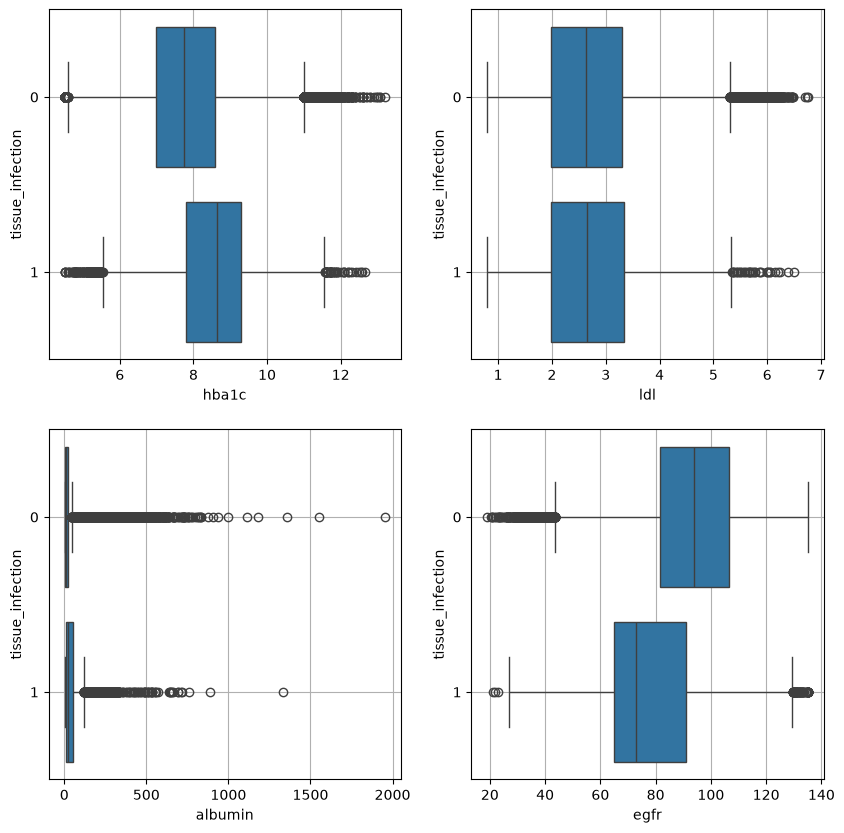

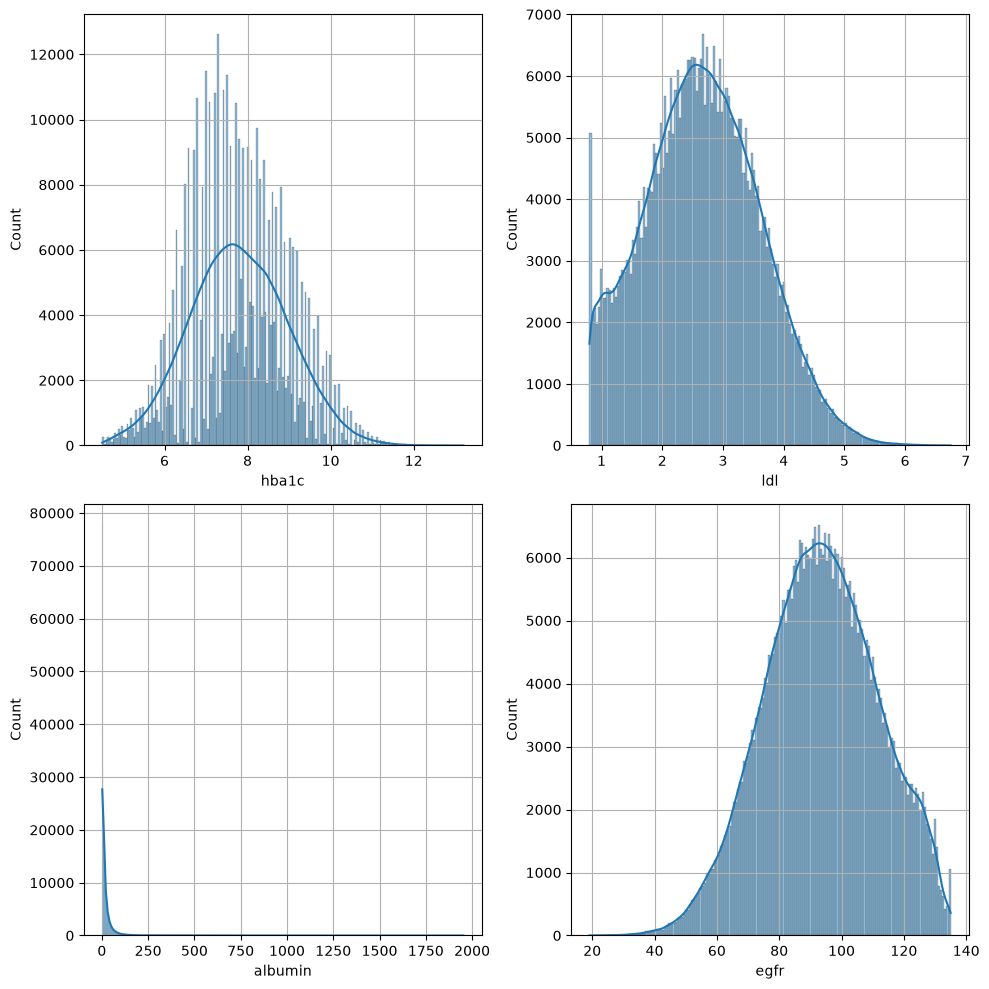

In [20]:
explore_outcome(outcome = "tissue_infection", _dict = dict_features, df = df_eda)

$1^{th}$ **Which variables are relevant for each of the four outcomes/complications?** </br>
After the data exploration phase, we define feature lists about each outcome as follows:
- `nephropathy`: [P8_male, R5_educ, hba1c, egfr, albumin, S20_ECI_CHF, S41_ECI_Obesity]
- `retinopathy`: [debut, P8_male, R5_educ, S1_CCI_Score, hba1c, ldl, albumin, egfr, smoking]
- `tissue_infection`: [P8_male, R5_educ, S1_CCI_score, S41_ECI_Obesity, hba1c, egfr, smoking, hh_glycemia]
- `cardiovascular`: [P8_male, R5_educ, S20_ECI_CHF, S41_ECI_Obesity, hba1c, ldl, albumin, egfr, smoking, acsc_heartf, acsc_angina]

Features `P8_male` and `R5_educ` are required in each list for **Task 9: Fairness Analyse**.

In [21]:
def list_of_features(outcome: str) -> list:
    '''
        Function used to get the list of features more related to the given outcome. \n
        **outcome**: outcome variable
    '''

    if outcome == "nephropathy":
        return ["P8_male", "R5_educ", "S20_ECI_CHF", "S41_ECI_Obesity", "hba1c", "albumin", "egfr"]
    elif outcome == "retinopathy":
        return ["debut", "P8_male", "R5_educ", "S1_CCI_Score", "S41_ECI_Obesity", "hba1c", "egfr", "ldl", "smoking"]
    elif outcome == "tissue_infection":
        return ["P8_male", "R5_educ", "S1_CCI_Score", "S41_ECI_Obesity", "hba1c", "egfr", "smoking", "hh_glycemia"]
    else:
        return ["P8_male", "R5_educ", "S20_ECI_CHF", "S41_ECI_Obesity", "hba1c", "egfr", "ldl", "smoking", "acsc_heartf", "acsc_angina"]

### Task 2: Instance kodning 

#### Task 2a: From monthly to quarterly data

In [22]:
# Dataframe `df` already sorted before
df_quarter = df.copy()

# Counting months for each patient, defined by the `groupby()` function
df_quarter["month_count"] = df_quarter.groupby("pnr").cumcount() + 1

# Creating the quarter id
df_quarter["period_id"] = np.ceil(df_quarter["month_count"] / 3).astype(int)

##### Task 2a.1: Check
- Every patient should have at most 20 `n_periods`.
- Each row combining together the same `pnr` and `period_id` should have a `period_id_count` up to 3.

In [ ]:
# Checking if the new dataset is correct or not
max_id = df_quarter.groupby("pnr")["period_id"].max()
print(f"Max quarters found from the new datatset: {set(max_id)}")

df_quarter["period_id_count"] = df_quarter.groupby(["pnr", "period_id"]).transform("size")

# Checking if each combinationn `pnr` and `period_id` has at most three observations
assert (df_quarter["period_id_count"] == 3).all(), "Something went wrong..."

Max quarters found from the new datatset: {20}


In [24]:
df_quarter = df_quarter.drop(["month_count", "period_id_count"], axis = 1)

In [25]:
display(df_quarter.head())

,pnr,debut,dob,P8_male,R5_educ,R25_DADI_9,G4_region_residence_name,R2_single,R3_childrenhome,R4_children18up,...,acsc_epi,acsc_copd,acsc_astma,acsc_heartf,acsc_angina,month_date,month,year_month,year,period_id
0,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,0,Syddanmark,0,1,5,...,0,0,0,0,0,2014-01-01 02:00:00+02:00,1,2014-01,2014,1
1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,1,Syddanmark,0,0,11,...,0,0,0,0,0,2014-02-01 02:00:00+02:00,2,2014-02,2014,1
2,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,1,Syddanmark,0,0,3,...,0,0,0,0,0,2014-03-01 02:00:00+02:00,3,2014-03,2014,1
3,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,0,Syddanmark,0,0,2,...,0,0,0,0,0,2014-04-01 03:00:00+03:00,4,2014-04,2014,2
4,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,1,Syddanmark,1,0,1,...,0,0,0,0,0,2014-05-01 03:00:00+03:00,5,2014-05,2014,2


#### Task 2b: Collapse to quarterly data

$1^{st}$ **Explain WHY we use different aggregation functions.** </br>
Since we are collapsing monthly observations into quarterly data, different types of variables or features require different mathematical representations to avoid losing critical information. 

In [26]:
agg = {
    "debut": "first",
    "dob": "first", 
    "P8_male": "first", 
    "R5_educ": "max", 
    "G4_region_residence_name": "first",
    "S1_CCI_score": "max", 
    "S20_ECI_CHF": "max", 
    "S41_ECI_Obesity": "max",
    "hba1c": "mean", 
    "ldl": "mean", 
    "albumin": "mean", 
    "egfr": "mean",
    "smoking": "max",
    "hh_glycemia": "max",
    "count_acute_hosp": "sum", 
    "count_elective_hosp": "sum",
    "count_inpat_hosp": "sum", 
    "count_outpat_hosp": "sum",
    "tissue_infection": "max", 
    "retinopathy": "max",
    "cardiovascular": "max", 
    "nephropathy": "max",
    "acsc_heartf": "max", 
    "acsc_angina": "max",
    "month_date": "first",
}

In [27]:
df_collapsing = df_quarter.copy()
df_collapsing = df_collapsing.groupby(["pnr", "period_id"]).agg(agg).reset_index()

In [28]:
df_collapsing.groupby("pnr").size().agg(["min","max"])

min    20
max    20
dtype: int64

In [29]:
display(df_collapsing.head())

,pnr,period_id,debut,dob,P8_male,R5_educ,G4_region_residence_name,S1_CCI_score,S20_ECI_CHF,S41_ECI_Obesity,...,count_elective_hosp,count_inpat_hosp,count_outpat_hosp,tissue_infection,retinopathy,cardiovascular,nephropathy,acsc_heartf,acsc_angina,month_date
0,1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,6,1,6,0,0,0,0,0,0,2014-01-01 02:00:00+02:00
1,1,2,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,1,...,2,0,2,0,0,0,0,0,0,2014-04-01 03:00:00+03:00
2,1,3,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,10,0,9,0,0,0,0,0,0,2014-07-01 03:00:00+03:00
3,1,4,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,11,0,10,0,0,0,0,0,0,2014-10-01 03:00:00+03:00
4,1,5,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,5,0,5,0,0,0,0,0,0,2015-01-01 02:00:00+02:00


#### Task 2c: Find the last period in which each individual is observed and the future periods for each individual

In [30]:
df_window = df_collapsing.copy()

periods = 12
df_window["future_period_id"] = df_window["period_id"] + periods

df_window["max_period"] = df_window.groupby("pnr")["period_id"].transform("max")

In [31]:
display(df_window.head())

,pnr,period_id,debut,dob,P8_male,R5_educ,G4_region_residence_name,S1_CCI_score,S20_ECI_CHF,S41_ECI_Obesity,...,count_outpat_hosp,tissue_infection,retinopathy,cardiovascular,nephropathy,acsc_heartf,acsc_angina,month_date,future_period_id,max_period
0,1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,6,0,0,0,0,0,0,2014-01-01 02:00:00+02:00,13,20
1,1,2,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,1,...,2,0,0,0,0,0,0,2014-04-01 03:00:00+03:00,14,20
2,1,3,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,9,0,0,0,0,0,0,2014-07-01 03:00:00+03:00,15,20
3,1,4,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,10,0,0,0,0,0,0,2014-10-01 03:00:00+03:00,16,20
4,1,5,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,5,0,0,0,0,0,0,2015-01-01 02:00:00+02:00,17,20


#### Task 2d: Predict Future Outcome

$1^{st}$ **Explain what buffer period means**. </br>
$\dots$

In [32]:
df_target = df_window.copy()

# `lead` in R corresponds to a negative shift in pandas, that's why I'm doing `-periods`
for y in ["tissue_infection", "retinopathy", "cardiovascular", "nephropathy"]:
    df_target[f"future_{y}"] = df_target.groupby("pnr")[y].shift(-periods).astype("Int64")

In [33]:
display(df_target.head())

,pnr,period_id,debut,dob,P8_male,R5_educ,G4_region_residence_name,S1_CCI_score,S20_ECI_CHF,S41_ECI_Obesity,...,nephropathy,acsc_heartf,acsc_angina,month_date,future_period_id,max_period,future_tissue_infection,future_retinopathy,future_cardiovascular,future_nephropathy
0,1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,0,0,0,2014-01-01 02:00:00+02:00,13,20,0,0,0,0
1,1,2,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,1,...,0,0,0,2014-04-01 03:00:00+03:00,14,20,0,1,0,0
2,1,3,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0,0,0,2014-07-01 03:00:00+03:00,15,20,0,0,0,0
3,1,4,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0,0,0,2014-10-01 03:00:00+03:00,16,20,0,0,0,0
4,1,5,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,0,0,0,2015-01-01 02:00:00+02:00,17,20,0,0,0,0


##### Task 2d.1: Check check

In [34]:
future_outcomes = ["future_tissue_infection", "future_retinopathy", "future_cardiovascular", "future_nephropathy"]

$1^{st}$ **How many NAS?**

In [35]:
number_of_null = df_target[future_outcomes].isna().sum()
print(f"After shifting the outcomes have {number_of_null.values[0]} missing values")

After shifting the outcomes have 996456 missing values


$2^{nd}$ **How common is the complication: 5%? 10%?**

In [ ]:
def computing_common_percentages(df: pd.DataFrame) -> str:
    '''
        Function used to compute percentages of the outcomes by row-level and patient-level. \n
        **df**: dataframe containing the observations
    ''' 

    # Number of patients
    n_patients = df["pnr"].nunique()

    table = []
    headers = ["outcome", "rows", "positives", "row-level", "patient-level"]
    for future_outcome in future_outcomes:
        # 1. Computing `How common is the complication between rows?`
        # 2. Computing `How many patients had at least one complication in the last 32 years?`

        # 1.
        n_valid = int(df[future_outcome].notna().sum())
        n_pos = int(df[future_outcome].sum())
        prev_row = round(n_pos / n_valid * 100, 2)

        # 2.
        counter = df[df[future_outcome] == 1]["pnr"].nunique()
        percentage = round((counter / n_patients) * 100, 2)

        table.append([f"{future_outcome}", n_valid, n_pos, f"{prev_row}%", f"{percentage}%"])

    return tabulate(tabular_data = table, headers = headers, numalign = "left", stralign = "left")

In [37]:
print(computing_common_percentages(df = df_target))

outcome                  rows    positives    row-level    patient-level
-----------------------  ------  -----------  -----------  ---------------
future_tissue_infection  664304  35720        5.38%        24.43%
future_retinopathy       664304  51869        7.81%        37.03%
future_cardiovascular    664304  59853        9.01%        43.3%
future_nephropathy       664304  45197        6.8%         25.32%


Observations:
- Percentage `row-level` describes how much the dataset over outcomes is imbalanced.
- These information provide us that we cannot use only `accuracy` metric to evaluate our model. 
- The last percentage `patient-level` defines how many patients had the outcome in the last two years. It's useful as additional detail, but it doesn't tell us anything about how much is imbalanced the dataset.

$3^{rd}$ **Does the logic hold when you inspect one patient?**

In [38]:
df_patient = df_target[df_target["pnr"] == 1]

In [ ]:
for outcome in outcomes:
    assert (df_patient[outcome][12:].values == df_patient[f"future_{outcome}"][:8].values).all(), "Something went wrong..."

In [40]:
print(computing_common_percentages(df = df_patient))

outcome                  rows    positives    row-level    patient-level
-----------------------  ------  -----------  -----------  ---------------
future_tissue_infection  8       0            0.0%         0.0%
future_retinopathy       8       1            12.5%        100.0%
future_cardiovascular    8       0            0.0%         0.0%
future_nephropathy       8       0            0.0%         0.0%


Observations:
- We obtain $100\%$ over patient-level cause we are considering only one specific patient, `pnr = 1`.
- The logic holds for the inspected patient (`pnr = 1`): **future_outcomes** equal the ordinary **outcomes** $12$ quarters later. However, percentages over one single patient cannot be expected to fall in the $5-10\%$ range: with $8$ rows it can be only $0\%$, $12,5\%$ and so on.

#### Task 2e: Rolling Features

In [ ]:
def window(df, col, w = 4):
    return pd.concat([df.groupby("pnr")[col].shift(-k) for k in range(w)], axis = 1)

$1^{st}$ **Which choice makes sense for your variables, and why?** </br>
As happened for collapsing, also the rolling phase is done taking in account the type of the feature. We follow a very simple behavior:
- Continuos values: `mean()`, taking the average value skipping `NaN` values.
- Counts: `sum()`, defining the total number in the quarter, since we put together months in quarters.
- Binary/Categorical values: `max()`, 

So, based on the type of the feature we use a different rolling function.

In [42]:
df_rolling = df_target.copy()

for binary in ["S1_CCI_score", "S20_ECI_CHF", "S41_ECI_Obesity", "hh_glycemia"]:
    df_rolling[f"{binary}_rolling"] = window(df_rolling, binary).max(axis = 1)

for count in ["count_acute_hosp", "count_elective_hosp","count_inpat_hosp", "count_outpat_hosp"]:
    df_rolling[f"{count}_rolling"] = window(df_rolling, count).sum(axis = 1, min_count = 1)

for continuos in ["hba1c", "ldl", "albumin", "egfr"]:
    df_rolling[f"{continuos}_rolling"] = window(df_rolling, continuos).mean(axis = 1)   

In [43]:
display(df_rolling.head())

,pnr,period_id,debut,dob,P8_male,R5_educ,G4_region_residence_name,S1_CCI_score,S20_ECI_CHF,S41_ECI_Obesity,...,S41_ECI_Obesity_rolling,hh_glycemia_rolling,count_acute_hosp_rolling,count_elective_hosp_rolling,count_inpat_hosp_rolling,count_outpat_hosp_rolling,hba1c_rolling,ldl_rolling,albumin_rolling,egfr_rolling
0,1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,1.0,0.0,0.0,29.0,1.0,27.0,7.792185,2.974946,4.044756,103.32700
1,1,2,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,1,...,1.0,0.0,0.0,28.0,0.0,26.0,7.752415,2.952596,4.074118,103.22700
2,1,3,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0.0,0.0,0.0,33.0,0.0,31.0,7.678364,2.929867,4.111714,103.32700
3,1,4,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0.0,0.0,0.0,25.0,0.0,25.0,7.675673,2.915680,4.138946,102.53575
4,1,5,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,1.0,0.0,1.0,16.0,1.0,17.0,7.733460,2.893236,4.116730,102.23375


#### Task 2f: Remove periods with an insufficient number of future observations

In [69]:
df_final = df_rolling.copy()

df_final["max_period_tt"] = df_final["max_period"] - periods
df_final = df_final[df_final["period_id"] <= df_final["max_period_tt"]].copy()

print(f"Final dataset has {df_final.shape[0]} rows and {df_final.shape[1]} columns")

Final dataset has 664304 rows and 46 columns


In [70]:
display(df_final.head())

,pnr,period_id,debut,dob,P8_male,R5_educ,G4_region_residence_name,S1_CCI_score,S20_ECI_CHF,S41_ECI_Obesity,...,hh_glycemia_rolling,count_acute_hosp_rolling,count_elective_hosp_rolling,count_inpat_hosp_rolling,count_outpat_hosp_rolling,hba1c_rolling,ldl_rolling,albumin_rolling,egfr_rolling,max_period_tt
0,1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,0.0,0.0,29.0,1.0,27.0,7.792185,2.974946,4.044756,103.32700,8
1,1,2,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,1,...,0.0,0.0,28.0,0.0,26.0,7.752415,2.952596,4.074118,103.22700,8
2,1,3,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0.0,0.0,33.0,0.0,31.0,7.678364,2.929867,4.111714,103.32700,8
3,1,4,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0.0,0.0,25.0,0.0,25.0,7.675673,2.915680,4.138946,102.53575,8
4,1,5,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,0.0,1.0,16.0,1.0,17.0,7.733460,2.893236,4.116730,102.23375,8


In [71]:
print(f"Number of missing values is {df_final.isna().sum(axis = 1).sum()}")

Number of missing values is 5655


In [72]:
x_1 = df.shape[0]
y_1 = df.shape[1]

x_2 = df_final.shape[0]
y_2 = df_final.shape[1]

print(f"After the data preparation phase we have {x_1} -> {x_2} rows and {y_1} -> {y_2} columns")

After the data preparation phase we have 4982280 -> 664304 rows and 40 -> 46 columns


### Task 3: Feature engineering

**Observations**:
- `RandomForest` and `Boosting` do not require to split continuos variables into groups.
- `LogisticRegression` should be positively influenced by splitting continuos features into groups.
- Shape of the relation between continuos feature and outcome.

In [ ]:
def get_continuos_features(df: pd.DataFrame, max_unique_ratio = 0.05) -> list:
    '''
        Function used to detect continuos features from the given dataframe. \n
        - **df**: dataframe containing all the observations
    '''

    numeric_features = df.select_dtypes(include = np.number)

    continuos_features = []
    for column in numeric_features.columns:
        feature = numeric_features[column]

        if feature.nunique() / len(df) > max_unique_ratio and "_rolling" in feature.name:
            continuos_features.append(feature.name)

    return continuos_features

In [ ]:
def clean_pair(feature: str, outcome: str, df: pd.DataFrame) -> pd.DataFrame:
    '''
        Function used to drop all missing values between selected feature and outcome. \n
        - **feature**: column or feature of the dataframe
        - **outcome**: outcome coming from the same dataframe
        - **df**: dataframe containing all the observations about
    '''
    
    return df[[feature, outcome]].dropna()

Three ways to interpret scatter plots by `regplot()` function:
1. Straight line, keep it continuos.
2. U-shape, split the feature into groups.
3. Step-shape, split the feature into groups.

In [ ]:
def examine_continuos_features(features: list, df: pd.DataFrame):
    '''
        Function used ... \n
        - **...**: 
    '''

    headers = ["outcome", "abs_diff", "pear", "spear"]
    for future_outcome in future_outcomes:
        table = []

        _, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (10, 10))
        axes = axes.ravel()

        for ax, feature in zip(axes, features):
            df_without_na = clean_pair(feature = feature, outcome = future_outcome, df = df)
            df_sample = df_without_na.sample(frac = 0.1, random_state = RANDOM_STATE)

            pear = pearsonr(x = df_without_na[feature], y = df_without_na[future_outcome])[0]
            spear = spearmanr(a = df_without_na[feature], b = df_without_na[future_outcome])[0]

            table.append([feature, future_outcome, abs(pear - spear), pear, spear])

            sns.regplot(data = df_sample, x = feature, y = future_outcome, scatter_kws={"alpha": 0.05, "s": 5}, ax = ax)

            ax.grid()

        print(tabulate(tabular_data = table, headers = headers, numalign = "left", stralign = "left"))

        plt.tight_layout()
        plt.show()

                 outcome                  abs_diff     pear        spear
---------------  -----------------------  -----------  ----------  ----------
hba1c_rolling    future_tissue_infection  0.00175033   0.121549    0.119799
ldl_rolling      future_tissue_infection  0.000304369  0.00215708  0.00185272
albumin_rolling  future_tissue_infection  0.0171057    0.141301    0.124195
egfr_rolling     future_tissue_infection  0.00738219   -0.168506   -0.161124


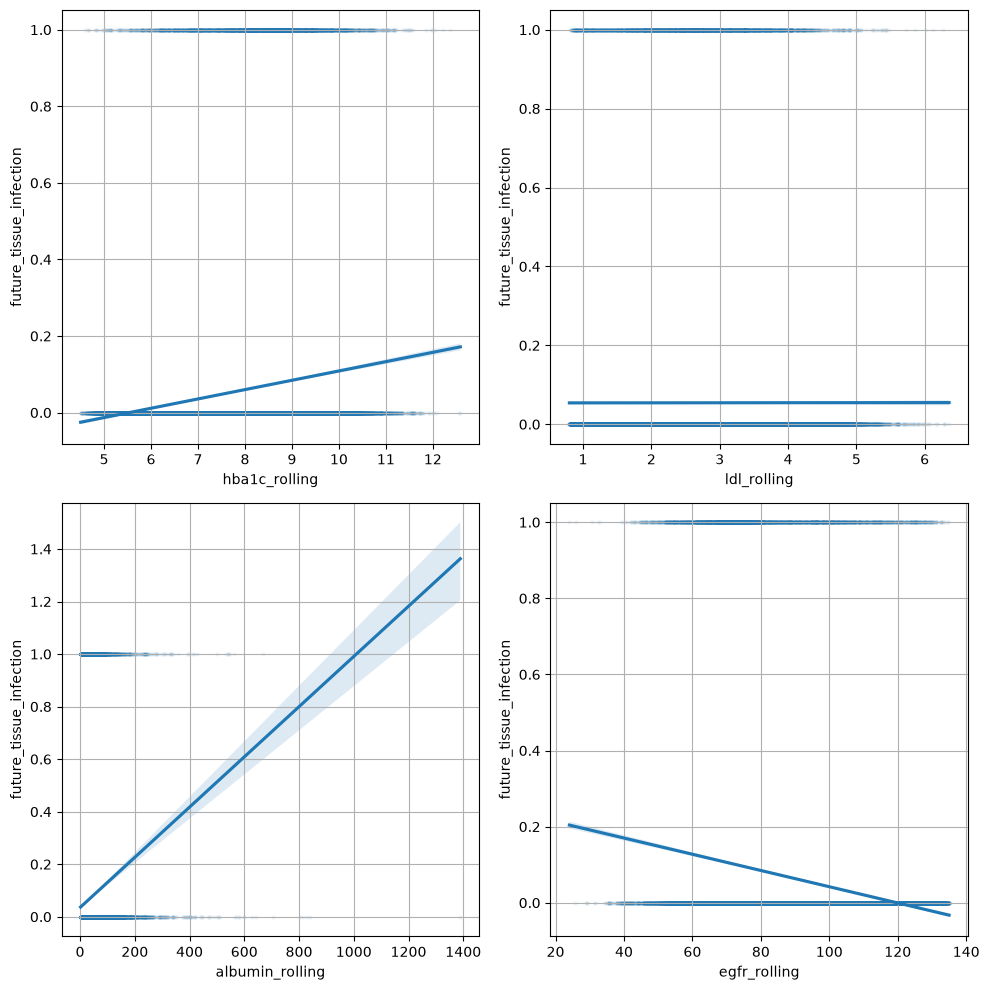

                 outcome             abs_diff     pear         spear
---------------  ------------------  -----------  -----------  -----------
hba1c_rolling    future_retinopathy  0.0117308    0.230271     0.218541
ldl_rolling      future_retinopathy  0.000324561  -0.00813374  -0.00845831
albumin_rolling  future_retinopathy  0.0124911    0.123081     0.135573
egfr_rolling     future_retinopathy  0.00218285   -0.101133    -0.0989497


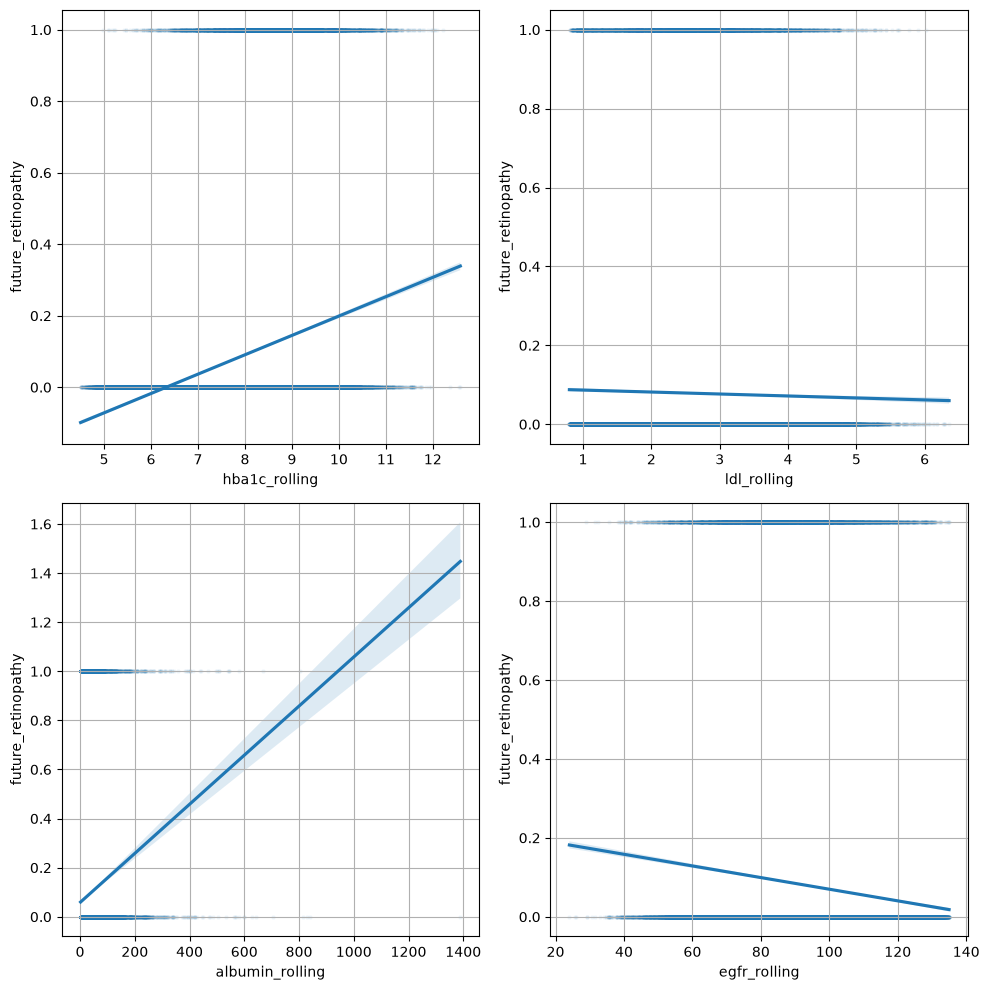

                 outcome                abs_diff     pear        spear
---------------  ---------------------  -----------  ----------  ----------
hba1c_rolling    future_cardiovascular  0.00175238   0.0214574   0.0197051
ldl_rolling      future_cardiovascular  0.00111929   0.0570915   0.0582108
albumin_rolling  future_cardiovascular  0.000870853  0.00119886  0.00032801
egfr_rolling     future_cardiovascular  0.000188496  0.00494164  0.00513013


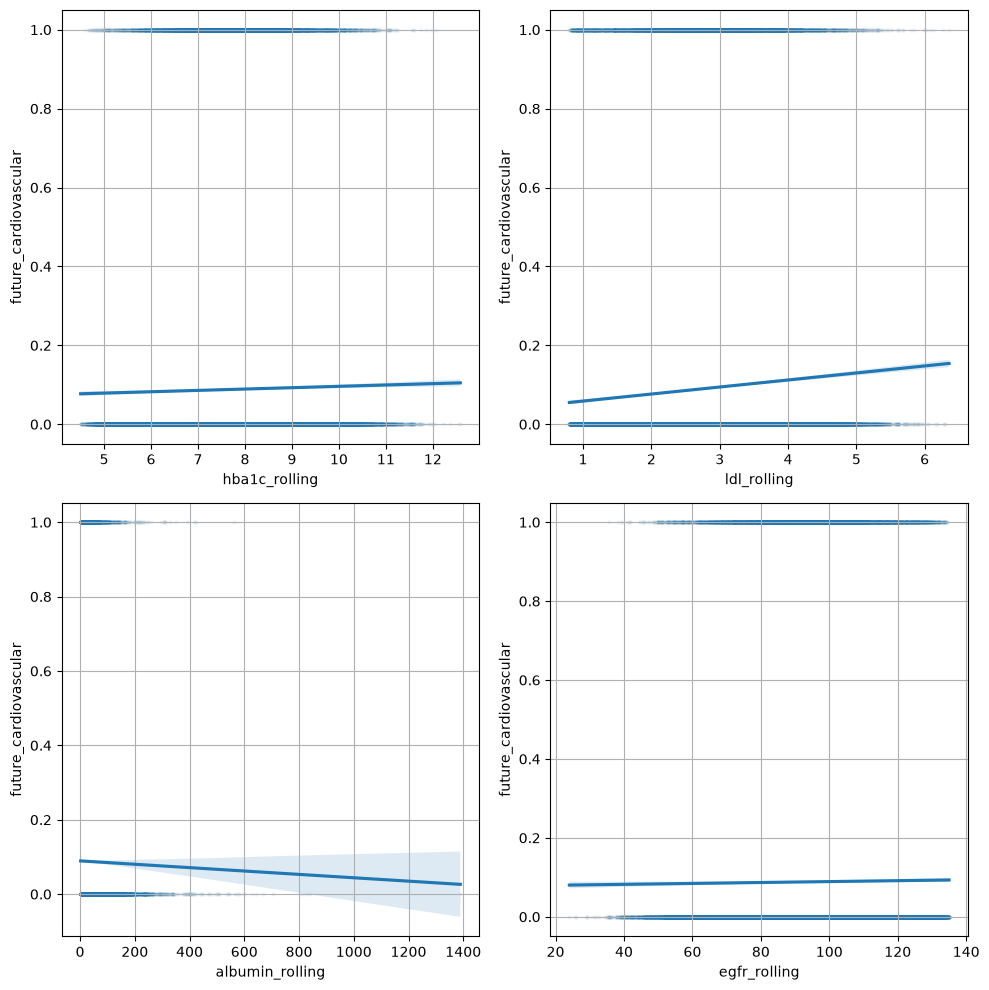

                 outcome             abs_diff     pear        spear
---------------  ------------------  -----------  ----------  ----------
hba1c_rolling    future_nephropathy  0.00731674   0.178703    0.171387
ldl_rolling      future_nephropathy  0.000189305  -0.0198796  -0.0200689
albumin_rolling  future_nephropathy  0.104262     0.424449    0.320187
egfr_rolling     future_nephropathy  0.0249382    -0.327107   -0.302169


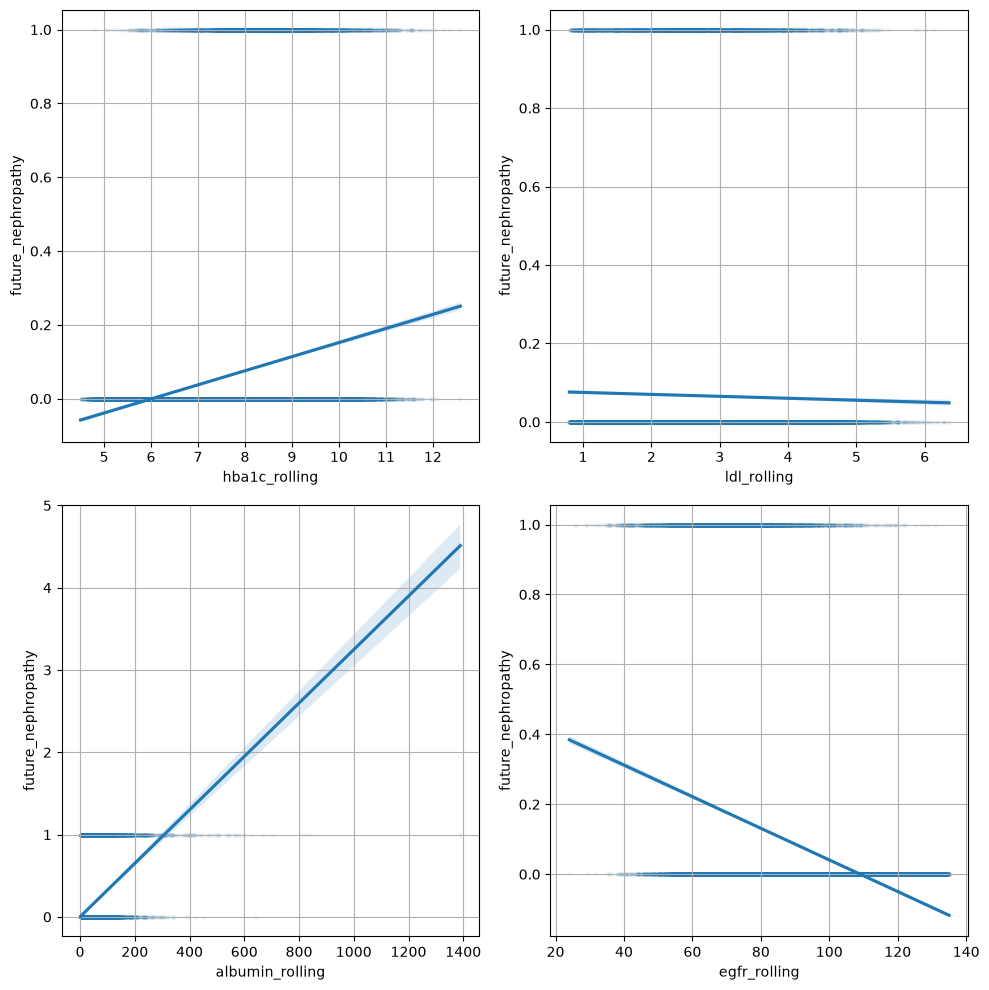

In [51]:
continuos_features = get_continuos_features(df = df_final)

if len(continuos_features) > 0:
    examine_continuos_features(features = continuos_features, df = df_final)

$1^{st}$ **Explain why or why not.** </br>
**Observations**:
- Never obtained a shape different from the straight line.
- The difference between Pearson and Spearman correlations never exceeds the linear limit ($< 0.05$), there is only one exception regarding (`albumin_rolling`-`future_nephropathy`).

**Final decision** $\rightarrow$ we don't need to split the continuos variables in groups.

### Task 4: One-hot encoding of categorical variables

Looking at the features of the dataset, there aren't so much categorical variables.

In [ ]:
def get_categorical_features(df: pd.DataFrame):
    '''
        Function used to detect categorical features from the given dataframe. \n
        - **df**: dataframe containing all the observations
    '''

    categorical_features = list()
    for column in df.columns:
        feature = df[column]

        if feature.dtype in ["object", "category", "string"]:
            categorical_features.append(feature.name)

    return categorical_features

In [73]:
def transform_categorical_in_binary(features: list, df: pd.DataFrame) -> pd.DataFrame:
    _ = pd.DataFrame()
    for feature in features:
        dummies = pd.get_dummies(df[feature]).astype("int")
        _ = pd.concat([_, dummies], axis = 1)

    return pd.concat([df, _], axis = 1)

In [74]:
categorical_features = get_categorical_features(df = df_final)

if len(categorical_features) > 0:
    df_final = transform_categorical_in_binary(features = categorical_features, df = df_final)

In [101]:
print(f"After One-Hot Encoding the final dataset has {df_final.shape[0]} rows and {df_final.shape[1]} columns")

After One-Hot Encoding the final dataset has 664304 rows and 49 columns


In [75]:
display(df_final.head())

,pnr,period_id,debut,dob,P8_male,R5_educ,G4_region_residence_name,S1_CCI_score,S20_ECI_CHF,S41_ECI_Obesity,...,count_inpat_hosp_rolling,count_outpat_hosp_rolling,hba1c_rolling,ldl_rolling,albumin_rolling,egfr_rolling,max_period_tt,Nordjylland,Sjælland,Syddanmark
0,1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,1.0,27.0,7.792185,2.974946,4.044756,103.32700,8,0,0,1
1,1,2,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,1,...,0.0,26.0,7.752415,2.952596,4.074118,103.22700,8,0,0,1
2,1,3,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0.0,31.0,7.678364,2.929867,4.111714,103.32700,8,0,0,1
3,1,4,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,Syddanmark,2,0,0,...,0.0,25.0,7.675673,2.915680,4.138946,102.53575,8,0,0,1
4,1,5,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,Syddanmark,2,0,0,...,1.0,17.0,7.733460,2.893236,4.116730,102.23375,8,0,0,1


$1^{st}$ **What does and is one-hot encoding?**

$2^{nd}$ **Why is it relevant in machine learning?**

### Task 5: Split data to machine learning
Splitting the data must be done on the IDs, not the row.

**Observations**:
- We have a huge class **imbalance**.
- So, we cannot split the dataset by rows but only by patient.
- A very good accuracy does not mean a great model, we have to use other metrics to state so.
- Suggestion is to use everything is coming from the **Confusion Matrix**, not focus only on accuracy!

In [110]:
ids = df_final["pnr"].unique()
train_ids = pd.Series(ids).sample(frac = 0.7, random_state = RANDOM_STATE).values

train_df = df[df["pnr"].isin(train_ids)]
test_df = df[~df["pnr"].isin(train_ids)]

In [112]:
# Checking if pnrs are shared between train set and test set
assert (train_df["pnr"].isin(test_df["pnr"]).sum() == 0), "Something went wrong..."

In [113]:
# Checking if the sum of rows between train set and test set is equal to the number of rows of the original dataframe `df_final`
assert ((train_df["pnr"].nunique() + test_df["pnr"].nunique()) == df_final["pnr"].nunique()), "Something went wrong..."

$1^{st}$ **Explain why you split as you do.**

## Part 2: Machine Learning

### Task 6: Choice of ML models

$1^{st}$ **Discuss which ML models are relevant, and asses theri advantages and disdvamtages on a theoretical basis.**

$2^{nd}$ **What is *class_imbalance*, and how does it affect the models?**

$3^{rd}$ **Which metric is most important: sensitivity, specificity or AUC?**

## Task 7: Carry out the ML models

In [ ]:
# Train models!